LLM Phase 1: without RAG

In [ ]:
import pandas as pd

df = pd.read_csv("requirements_dataset.csv")
from sklearn.model_selection import train_test_split

# Stratified split — preserves class balance in both sets
prompt_dev_df, eval_df = train_test_split(
    df,
    test_size=0.85,        # 85% for evaluation, 15% for prompt dev
    stratify=df["DetectedAs"],  # keeps AMBIGUOUS/CLEAR ratio the same in both
    random_state=42
)

print(f"Prompt dev set : {len(prompt_dev_df)}")
print(f"Evaluation set : {len(eval_df)}")
print("\nPrompt dev label distribution:")
print(prompt_dev_df["DetectedAs"].value_counts())
print("\nEvaluation label distribution:")
print(eval_df["DetectedAs"].value_counts())

# Save them separately so you don't accidentally mix them
prompt_dev_df.to_csv("prompt_dev.csv", index=False)
eval_df.to_csv("eval_set.csv", index=False)

Prompt dev set : 110
Evaluation set : 627

Prompt dev label distribution:
DetectedAs
unambiguous    59
ambiguous      51
Name: count, dtype: int64

Evaluation label distribution:
DetectedAs
unambiguous    336
ambiguous      291
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Pick 5 AMBIGUOUS + 5 UNAMBIGUOUS from prompt_dev_df
# Use requirements you are confident about — clear cut cases only
examples_ambiguous = prompt_dev_df[
    prompt_dev_df["DetectedAs"].str.upper() == "AMBIGUOUS"
].head(5)

examples_unambiguous = prompt_dev_df[
    prompt_dev_df["DetectedAs"].str.upper() == "UNAMBIGUOUS"
].head(5)

shot_examples = pd.concat([examples_ambiguous, examples_unambiguous]).reset_index(drop=True)

print("10-shot examples:")
for _, row in shot_examples.iterrows():
    print(f"  [{row['DetectedAs'].upper()}] {row['Context'][:80]}...")

In [ ]:
# Mapping — run this once so you don't have to remember
MODEL_TYPE_MAP = {
    "mistral7b"    : "qwen",       # ChatML format
    "croissant"    : "qwen",       # ChatML format
    "eurollm"      : "qwen",       # ChatML format
    "qwen"         : "qwen",       # ChatML format
    "phi"          : "phi",        # Phi format
    "llama"        : "llama",      # Llama format
    "mistral_api"  : "mistral_api" # API — handled separately
}

In [ ]:
def build_10shot_prompt(requirement: str, examples_df, model_type: str) -> str:

    system_instruction = """As a requirements engineer, you are tasked with evaluating project specifications.
For each requirement, please follow these steps:
1. Classification: Determine if the requirement is Ambiguous or Unambiguous.
2. Rationale: Briefly explain your classification in 1-3 sentences.
For Ambiguous requirements, identify vague terms or missing details.
For Unambiguous requirements, identify what makes it clear and complete.
Below are example requirements with their ground truth labels."""

    # Build demonstration blocks per model format
    demos = ""
    for _, row in examples_df.iterrows():
        label = row["DetectedAs"].strip().capitalize()  # Ambiguous / Unambiguous
        req = row["Context"].strip()

        if model_type in ["qwen", "eurollm","croissant"]:
            demos += f"""<|im_start|>user
{req}<|im_end|>
<|im_start|>assistant
Classification: {label}
Rationale:
<|im_end|>
"""
        elif model_type == "phi":
            demos += f"""<|user|>
{req}<|end|>
<|assistant|>
Classification: {label}
Rationale:
<|end|>
"""
        elif model_type == "llama":
            demos += f"""<|start_header_id|>user<|end_header_id|>
{req}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
Classification: {label}
Rationale:
<|eot_id|>"""

    # Final prompt with query requirement
    if model_type in ["qwen", "eurollm","croissant"]:
        prompt = f"""<|im_start|>system
{system_instruction}<|im_end|>
{demos}<|im_start|>user
{requirement}<|im_end|>
<|im_start|>assistant
Classification:"""

    elif model_type == "phi":
        prompt = f"""<|system|>
{system_instruction}<|end|>
{demos}<|user|>
{requirement}<|end|>
<|assistant|>
Classification:"""

    elif model_type == "llama":
        prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
{system_instruction}<|eot_id|>
{demos}<|start_header_id|>user<|end_header_id|>
{requirement}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
Classification:"""

    elif model_type == "mistral_api":
        # For API — build as messages list, handled separately
        return None

    return prompt

In [ ]:
import re

def classify_10shot(requirement: str, examples_df, model_type: str) -> dict:
    prompt = build_10shot_prompt(requirement, examples_df, model_type)

    if model_type in ["qwen", "eurollm","croissant"]:
        stop_tokens = ["<|im_end|>", "<|im_start|>"]
    elif model_type == "phi":
        stop_tokens = ["<|end|>", "<|user|>"]
    elif model_type == "llama":
        stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

    out = llm(
        prompt,
        max_tokens=80,       # more tokens to allow rationale
        temperature=0.0,     # paper used temperature=0
        stop=stop_tokens,
        echo=False
    )

    raw = out["choices"][0]["text"].strip()

    # Extract classification label
    raw_upper = raw.upper()
    if "UNAMBIGUOUS" in raw_upper:
        label = "UNAMBIGUOUS"
    elif "AMBIGUOUS" in raw_upper:
        label = "AMBIGUOUS"
    else:
        label = "ERROR"

    # Extract rationale if present
    reason = ""
    lines = raw.split("\n")
    for i, line in enumerate(lines):
        if "rationale" in line.lower() and i + 1 < len(lines):
            reason = lines[i + 1].strip()
            break
    if not reason and len(lines) > 1:
        reason = lines[-1].strip()

    return {
        "predicted"  : label,
        "reason"     : reason,
        "raw_output" : raw
    }

In [ ]:
import requests, json, re

def classify_10shot_api(requirement: str, examples_df) -> dict:
    # Build few-shot messages
    messages = []

    # System message
    messages.append({
        "role": "system",
        "content": """As a requirements engineer, evaluate project specifications.
For each requirement:
1. Classification: Ambiguous or Unambiguous
2. Rationale: one sentence explanation
Ambiguous: vague terms, no measurable criteria.
Unambiguous: specific numbers, thresholds, measurable conditions."""
    })

    # Add 10 examples as alternating user/assistant turns
    for _, row in examples_df.iterrows():
        label = row["DetectedAs"].strip().capitalize()
        messages.append({"role": "user", "content": row["Context"].strip()})
        messages.append({
            "role": "assistant",
            "content": f"Classification: {label}\nRationale:"
        })

    # Add the actual query
    messages.append({"role": "user", "content": requirement})

    response = requests.post(
        "https://api.mistral.ai/v1/chat/completions",
        headers={"Authorization": f"Bearer {API_KEY}"},
        json={
            "model": "mistral-small-latest",
            "messages": messages,
            "max_tokens": 100,
            "temperature": 0.0
        }
    )

    raw = response.json()["choices"][0]["message"]["content"].strip()
    raw_upper = raw.upper()

    if "UNAMBIGUOUS" in raw_upper:
        label = "UNAMBIGUOUS"
    elif "AMBIGUOUS" in raw_upper:
        label = "AMBIGUOUS"
    else:
        label = "ERROR"

    reason = ""
    lines = raw.split("\n")
    for i, line in enumerate(lines):
        if "rationale" in line.lower() and i + 1 < len(lines):
            reason = lines[i + 1].strip()
            break

    return {"predicted": label, "reason": reason, "raw_output": raw}

In [ ]:
from tqdm import tqdm
import pandas as pd
import time

def run_evaluation_10shot(dataset_df, examples_df, model_type: str, model_name: str):
    results = []

    for row in tqdm(dataset_df.itertuples(index=False), total=len(dataset_df)):
        try:
            if model_type == "mistral_api":
                result = classify_10shot_api(row.Context, examples_df)
                time.sleep(0.3)  # rate limit
            else:
                result = classify_10shot(row.Context, examples_df, model_type)

            results.append({
                "requirement"  : row.Context,
                "ground_truth" : row.DetectedAs,
                "predicted"    : result["predicted"],
                "reason"       : result.get("reason", ""),
                "raw_output"   : result.get("raw_output", "")
            })
        except Exception as e:
            results.append({
                "requirement"  : row.Context,
                "ground_truth" : row.DetectedAs,
                "predicted"    : "ERROR",
                "reason"       : str(e),
                "raw_output"   : ""
            })

        # checkpoint every 20
        if len(results) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_10shot.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_10shot.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_results(dev_results, model_name: str):
    # Normalise both columns to uppercase
    dev_results["predicted_clean"]    = dev_results["predicted"].str.strip().str.upper()
    dev_results["ground_truth_clean"] = dev_results["ground_truth"].str.strip().str.upper()

    # Filter errors
    clean = dev_results[dev_results["predicted_clean"] != "ERROR"].copy()
    print(f"\n========== {model_name} ==========")
    print(f"Valid predictions : {len(clean)}")
    print(f"Errors            : {len(dev_results) - len(clean)}")

    y_true = clean["ground_truth_clean"]
    y_pred = clean["predicted_clean"]

    print(f"\nAccuracy: {accuracy_score(y_true, y_pred):.4f}")
    print("\n" + classification_report(
        y_true, y_pred,
        labels=["AMBIGUOUS", "UNAMBIGUOUS"],
        target_names=["AMBIGUOUS", "UNAMBIGUOUS"]
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=["AMBIGUOUS", "UNAMBIGUOUS"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["AMBIGUOUS", "UNAMBIGUOUS"],
                yticklabels=["AMBIGUOUS", "UNAMBIGUOUS"])
    plt.xlabel("Predicted")
    plt.ylabel("Ground Truth")
    plt.title(f"{model_name} — confusion matrix")
    plt.tight_layout()
    plt.show()

    return accuracy_score(y_true, y_pred)

# Mistral 7B Quantized - 10 shot

Mistral 7B Quantized

In [ ]:
!pip install llama-cpp-python -q
!pip install huggingface_hub -q
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

model_path = hf_hub_download(
    repo_id="TheBloke/Mistral-7B-Instruct-v0.2-GGUF",
    filename="mistral-7b-instruct-v0.2.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

# Step 2 — load model
llm = Llama(
    model_path=model_path,
    n_ctx=4096,            # needs larger context for 10-shot
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)
print("Mistral 7B loaded")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.0/59.0 MB 10.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.5 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


mistral-7b-instruct-v0.2.Q4_K_M.gguf:   0%|          | 0.00/4.37G [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--TheBloke--Mistral-7B-Instruct-v0.2-GGUF/snapshots/3a6fbf4a41a1d52e415a4958cde6856d34b2db93/mistral-7b-instruct-v0.2.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


Mistral 7B loaded


In [ ]:
# Sanity check first for whichever model is loaded
for req, expected in [
    ("The system should load quickly", "AMBIGUOUS"),
    ("The login page must load within 2 seconds on a 10 Mbps connection", "UNAMBIGUOUS"),
    ("The UI should be user-friendly", "AMBIGUOUS"),
]:
    result = classify_10shot(req, shot_examples, model_type="phi")  # change per model
    status = "✓" if result["predicted"] == expected else "✗"
    print(f"{status} Expected: {expected} | Got: {result['predicted']}")
    print(f"   Reason: {result['reason']}\n")


✓ Expected: AMBIGUOUS | Got: AMBIGUOUS
   Reason: The term "quickly" is vague and does not provide a clear definition of what constitutes an acceptable loading time.

✓ Expected: UNAMBIGUOUS | Got: UNAMBIGUOUS
   Reason: Rationale:

✓ Expected: AMBIGUOUS | Got: AMBIGUOUS
   Reason: The term "user-friendly" is subjective and can vary greatly depending on the user's experience, preferences, and abilities. It would be helpful to define specific criteria for what makes the UI user-friendly, such as intuitive navigation, clear and concise information, and easy-to-use features.



In [ ]:
# Mistral 7B
dev_results_mistral7b_10shot = run_evaluation_10shot(
    prompt_dev_df, shot_examples,
    model_type="qwen",           # ChatML
    model_name="mistral7b"
)

100%|██████████| 110/110 [1:22:18<00:00, 44.90s/it]

Done. Errors: 0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



========== Mistral-7B-Instruct — 10-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.5364

              precision    recall  f1-score   support

   AMBIGUOUS       0.00      0.00      0.00        51
 UNAMBIGUOUS       0.54      1.00      0.70        59

    accuracy                           0.54       110
   macro avg       0.27      0.50      0.35       110
weighted avg       0.29      0.54      0.37       110



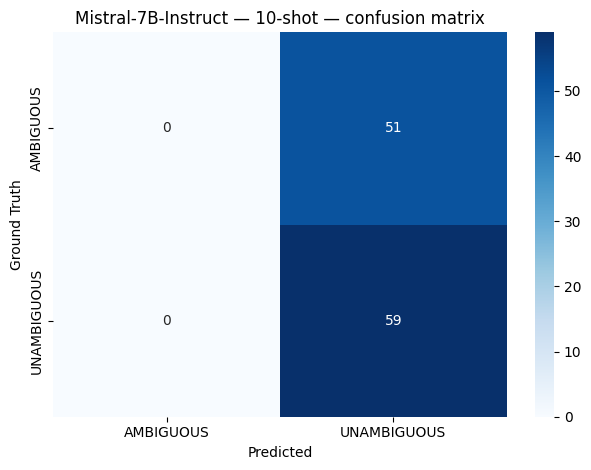

0.5363636363636364

In [ ]:
evaluate_results(dev_results_mistral7b_10shot, "Mistral-7B-Instruct — 10-shot")

In [ ]:
model_path = hf_hub_download(
    repo_id="croissantllm/CroissantLLMChat-v0.1-GGUF",
    filename="croissantllmchat-v0.1.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

llm = Llama(
    model_path=model_path,
    n_ctx=4096,            # needs larger context for 10-shot
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)

print("CroissantLLM loaded")

croissantllmchat-v0.1.Q4_K_M.gguf:   0%|          | 0.00/872M [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--croissantllm--CroissantLLMChat-v0.1-GGUF/snapshots/eb629e449909fe694e0699cad2a2f04578fddfaa/croissantllmchat-v0.1.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) > n_ctx_train (2048) -- possible training context overflow


CroissantLLM loaded


In [ ]:
 #Sanity check first for whichever model is loaded
for req, expected in [
    ("The system should load quickly", "AMBIGUOUS"),
    ("The login page must load within 2 seconds on a 10 Mbps connection", "UNAMBIGUOUS"),
    ("The UI should be user-friendly", "AMBIGUOUS"),
]:
    result = classify_10shot(req, shot_examples, model_type="croissant")  # change per model
    status = "✓" if result["predicted"] == expected else "✗"
    print(f"{status} Expected: {expected} | Got: {result['predicted']}")
    print(f"   Reason: {result['reason']}\n")


✗ Expected: AMBIGUOUS | Got: UNAMBIGUOUS
   Reason: The system should be able to handle a large number of requests simultaneously.

✓ Expected: UNAMBIGUOUS | Got: UNAMBIGUOUS
   Reason: The system shall provide a user-friendly interface for the user to select the desired data item and to view the relevant data in the form of a graph or chart.

✓ Expected: AMBIGUOUS | Got: AMBIGUOUS
   Reason: The system shall provide a user-friendly interface for the user to navigate through the system.



In [ ]:
# CroissantLLM
dev_results_croissant_10shot = run_evaluation_10shot(
    prompt_dev_df, shot_examples,
    model_type="qwen",           # ChatML
    model_name="croissant"
)

 18%|█▊        | 20/110 [05:27<26:57, 17.98s/it]

In [ ]:
evaluate_results(dev_results_croissant_10shot, "CroissantLLM — 10-shot")

EuroLLM

In [ ]:
!pip install llama-cpp-python -q
!pip install huggingface_hub -q
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

model_path = hf_hub_download(
    repo_id="QuantFactory/EuroLLM-1.7B-Instruct-GGUF",
    filename="EuroLLM-1.7B-Instruct.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

llm = Llama(
    model_path=model_path,
    n_ctx=4096,            # needs larger context for 10-shot
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)

print("EuroLLM loaded")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


EuroLLM-1.7B-Instruct.Q4_K_M.gguf:   0%|          | 0.00/1.05G [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--QuantFactory--EuroLLM-1.7B-Instruct-GGUF/snapshots/4126f034ddfe7fd39ca3378ae58d3b1d74065315/EuroLLM-1.7B-Instruct.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) < n_ctx_train (8192) -- the full capacity of the model will not be utilized


EuroLLM loaded


In [ ]:
 #Sanity check first for whichever model is loaded
for req, expected in [
    ("The system should load quickly", "AMBIGUOUS"),
    ("The login page must load within 2 seconds on a 10 Mbps connection", "UNAMBIGUOUS"),
    ("The UI should be user-friendly", "AMBIGUOUS"),
]:
    result = classify_10shot(req, shot_examples, model_type="eurollm")  # change per model
    status = "✓" if result["predicted"] == expected else "✗"
    print(f"{status} Expected: {expected} | Got: {result['predicted']}")
    print(f"   Reason: {result['reason']}\n")

✗ Expected: AMBIGUOUS | Got: UNAMBIGUOUS
   Reason: Rationale:

✓ Expected: UNAMBIGUOUS | Got: UNAMBIGUOUS
   Reason: Rationale:

✗ Expected: AMBIGUOUS | Got: UNAMBIGUOUS
   Reason: Rationale:



In [ ]:
# EuroLLM 1.7B
dev_results_euro_10shot = run_evaluation_10shot(
    prompt_dev_df, shot_examples,
    model_type="qwen",           # ChatML
    model_name="eurollm_1.7b"
)

100%|██████████| 110/110 [11:34<00:00,  6.31s/it]

Done. Errors: 0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



========== EuroLLM — 10-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.5364

              precision    recall  f1-score   support

   AMBIGUOUS       0.00      0.00      0.00        51
 UNAMBIGUOUS       0.54      1.00      0.70        59

    accuracy                           0.54       110
   macro avg       0.27      0.50      0.35       110
weighted avg       0.29      0.54      0.37       110



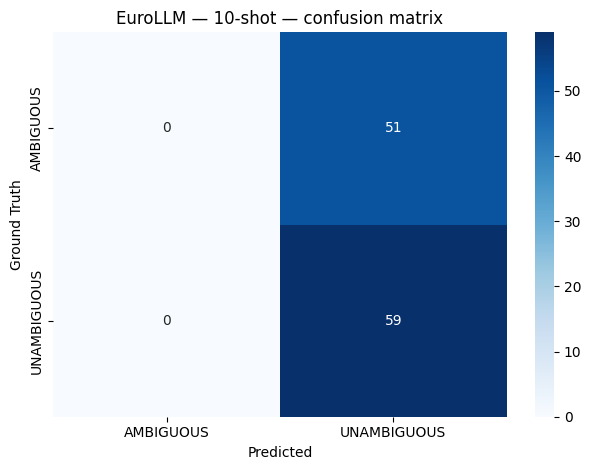

0.5363636363636364

In [ ]:
evaluate_results(dev_results_euro_10shot, "EuroLLM — 10-shot")

Mistral API

In [ ]:
import requests
import json
import re

API_KEY = "#################################"

In [ ]:
#Sanity check first for whichever model is loaded
for req, expected in [
    ("The system should load quickly", "AMBIGUOUS"),
    ("The login page must load within 2 seconds on a 10 Mbps connection", "UNAMBIGUOUS"),
    ("The UI should be user-friendly", "AMBIGUOUS"),
]:
    result = classify_10shot_api(req, shot_examples)  # change per model
    status = "✓" if result["predicted"] == expected else "✗"
    print(f"{status} Expected: {expected} | Got: {result['predicted']}")
    print(f"   Reason: {result['reason']}\n")

✓ Expected: AMBIGUOUS | Got: AMBIGUOUS
   Reason: 

✓ Expected: UNAMBIGUOUS | Got: UNAMBIGUOUS
   Reason: 

✓ Expected: AMBIGUOUS | Got: AMBIGUOUS
   Reason: 



In [ ]:
dev_results_api_10shot = run_evaluation_10shot(
    prompt_dev_df, shot_examples, model_type="mistral_api", model_name="mistral_api"
)

100%|██████████| 110/110 [01:36<00:00,  1.14it/s]

Done. Errors: 14



========== MitsralAPI — 10-shot ==========
Valid predictions : 96
Errors            : 14

Accuracy: 0.5000

              precision    recall  f1-score   support

   AMBIGUOUS       0.48      0.52      0.50        46
 UNAMBIGUOUS       0.52      0.48      0.50        50

    accuracy                           0.50        96
   macro avg       0.50      0.50      0.50        96
weighted avg       0.50      0.50      0.50        96



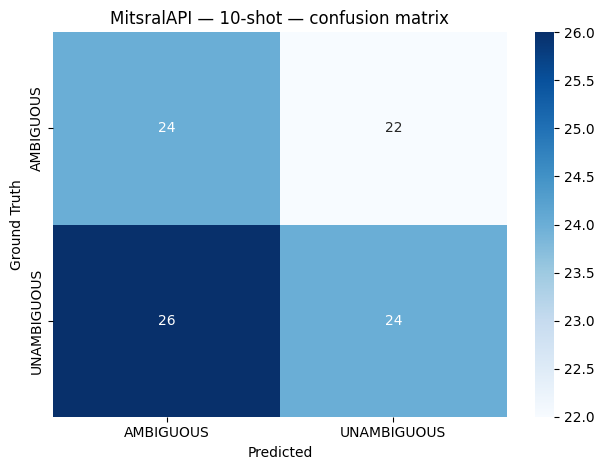

0.5

In [ ]:
evaluate_results(dev_results_api_10shot, "MitsralAPI — 10-shot")

In [ ]:
import json
import re

def classify_fewshot_detailed(requirement: str, model_type: str) -> dict:

    prompt = f"""
You are an expert in software requirement analysis.
A requirement is ambiguous if it introduces real uncertainty in understanding
A requirement is ambiguous if:
- It uses vague terms (e.g., "quickly", "efficiently") that affect interpreta
- It has unclear pronoun references (e.g., "it", "they")
- It allows multiple reasonable interpretations
A requirement is NOT ambiguous if:
- It is understandable by an engineer
- It follows standard engineering wording
- It contains general terms that do not affect implementation
IMPORTANT:
- Do NOT classify as ambiguous for minor wording issues
- Do NOT classify as ambiguous just because the sentence is complex
- Do NOT ignore clear ambiguity
Be balanced:
- If ambiguity clearly affects understanding → ambiguous
- Otherwise → unambiguous

Examples:

Requirement: HCCS ISS Work will also be synchronized with RCN and Halifax-class related activities, and managed within the related DND business plans and budgets. The Contractor must incorporate Canada's objectives into its ISS Program, without limiting or affecting any other provision of the Contract.
Classification: ambiguous

Requirement: The Contractor must provide in the Risk Management Plan, a risk management framework that provides a governance structure by which risks are escalated to the appropriate decision level in a timely manner to permit mitigation steps and actions to be implemented. The Contractor must include a Business Continuity Section as part of his Risk Management Plan.
Classification: ambiguous

Requirement: The Relationship Charter describes common goals, desired behaviours, and joint governance. It will include a series of mutually agreed upon processes to increase collaboration.
Classification: unambiguous

Requirement: Commencing at Contract Award, the Contractor must collect performance data to support the PMF. The Contractor must develop and update a Performance Management Plan that describes how the Contractor will manage their performance for the duration of the Contract.
Classification: unambiguous

Return ONLY JSON:
{{
  "classification": "ambiguous or unambiguous",
  "explanation": "one clear sentence"
}}

Requirement:
"{requirement}"
"""

    # Wrap in correct chat format per model
    if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
        full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
        stop_tokens = ["<|im_end|>", "<|im_start|>"]

    elif model_type == "phi":
        full_prompt = f"""<|system|>
You are an expert in software requirement analysis.<|end|>
<|user|>
{prompt}<|end|>
<|assistant|>
"""
        stop_tokens = ["<|end|>", "<|user|>"]

    elif model_type == "llama":
        full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
        stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    out = llm(
        full_prompt,
        max_tokens=120,
        temperature=0.0,
        stop=stop_tokens,
        echo=False
    )

    raw = out["choices"][0]["text"].strip()

    # Parse JSON response
    try:
        match = re.search(r'\{.*?\}', raw, re.DOTALL)
        if match:
            parsed = json.loads(match.group())
            label = parsed.get("classification", "ERROR").strip().lower()
            explanation = parsed.get("explanation", "")

            if "unambiguous" in label:
                final_label = "UNAMBIGUOUS"
            elif "ambiguous" in label:
                final_label = "AMBIGUOUS"
            else:
                final_label = "ERROR"

            return {
                "predicted"   : final_label,
                "explanation" : explanation,
                "raw_output"  : raw
            }
    except (json.JSONDecodeError, AttributeError):
        pass

    # Fallback — try to extract label from plain text if JSON fails
    raw_upper = raw.upper()
    if "UNAMBIGUOUS" in raw_upper:
        return {"predicted": "UNAMBIGUOUS", "explanation": "", "raw_output": raw}
    elif "AMBIGUOUS" in raw_upper:
        return {"predicted": "AMBIGUOUS", "explanation": "", "raw_output": raw}

    return {"predicted": "ERROR", "explanation": "", "raw_output": raw}

In [ ]:
from tqdm import tqdm
import pandas as pd
import time
def run_evaluation_fewshot(dataset_df, model_type: str, model_name: str):
    results = []

    for row in tqdm(dataset_df.itertuples(index=False), total=len(dataset_df)):
        try:
            if model_type == "mistral_api":
                result = classify_fewshot_detailed_api(row.Context)
                time.sleep(0.3)
            else:
                result = classify_fewshot_detailed(row.Context, model_type)

            results.append({
                "requirement"  : row.Context,
                "ground_truth" : row.DetectedAs,
                "predicted"    : result["predicted"],
                "explanation"  : result.get("explanation", ""),
                "raw_output"   : result.get("raw_output", "")
            })
        except Exception as e:
            results.append({
                "requirement"  : row.Context,
                "ground_truth" : row.DetectedAs,
                "predicted"    : "ERROR",
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        if len(results) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_fewshot.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_fewshot.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_results(dev_results, model_name: str):
    # Normalise both columns to uppercase
    dev_results["predicted_clean"]    = dev_results["predicted"].str.strip().str.upper()
    dev_results["ground_truth_clean"] = dev_results["ground_truth"].str.strip().str.upper()

    # Filter errors
    clean = dev_results[dev_results["predicted_clean"] != "ERROR"].copy()
    print(f"\n========== {model_name} ==========")
    print(f"Valid predictions : {len(clean)}")
    print(f"Errors            : {len(dev_results) - len(clean)}")

    y_true = clean["ground_truth_clean"]
    y_pred = clean["predicted_clean"]

    print(f"\nAccuracy: {accuracy_score(y_true, y_pred):.4f}")
    print("\n" + classification_report(
        y_true, y_pred,
        labels=["AMBIGUOUS", "UNAMBIGUOUS"],
        target_names=["AMBIGUOUS", "UNAMBIGUOUS"]
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=["AMBIGUOUS", "UNAMBIGUOUS"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["AMBIGUOUS", "UNAMBIGUOUS"],
                yticklabels=["AMBIGUOUS", "UNAMBIGUOUS"])
    plt.xlabel("Predicted")
    plt.ylabel("Ground Truth")
    plt.title(f"{model_name} — confusion matrix")
    plt.tight_layout()
    plt.show()

    return accuracy_score(y_true, y_pred)

MISTRAL7B

In [ ]:
!pip install llama-cpp-python -q
!pip install huggingface_hub -q
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

model_path = hf_hub_download(
    repo_id="TheBloke/Mistral-7B-Instruct-v0.2-GGUF",
    filename="mistral-7b-instruct-v0.2.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

# Step 2 — load model
llm = Llama(
    model_path=model_path,
    n_ctx=4096,            # needs larger context for 10-shot
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)
print("Mistral 7B loaded")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.0/59.0 MB 15.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.5 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


mistral-7b-instruct-v0.2.Q4_K_M.gguf:   0%|          | 0.00/4.37G [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--TheBloke--Mistral-7B-Instruct-v0.2-GGUF/snapshots/3a6fbf4a41a1d52e415a4958cde6856d34b2db93/mistral-7b-instruct-v0.2.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


Mistral 7B loaded


In [ ]:
for req, expected in [
    ("The system should load quickly", "AMBIGUOUS"),
    ("The login page must load within 2 seconds on a 10 Mbps connection", "UNAMBIGUOUS"),
    ("The UI should be user-friendly", "AMBIGUOUS"),
]:
    result = classify_fewshot_detailed(req, model_type="mistral7b")  # change per model
    status = "✓" if result["predicted"] == expected else "✗"
    print(f"{status} Expected: {expected} | Got: {result['predicted']}")
    print(f"   Explanation: {result['explanation']}")
    print(f"   RAW: {result['raw_output'][:80]}\n")

✓ Expected: AMBIGUOUS | Got: AMBIGUOUS
   Explanation: The term 'quickly' is vague and can be subjectively interpreted.
   RAW: {
  "classification": "ambiguous",
  "explanation": "The term 'quickly' is vague

✗ Expected: UNAMBIGUOUS | Got: AMBIGUOUS
   Explanation: The term 'within 2 seconds' is vague and can be subjectively interpreted.
   RAW: {
  "classification": "ambiguous",
  "explanation": "The term 'within 2 seconds'

✗ Expected: AMBIGUOUS | Got: UNAMBIGUOUS
   Explanation: The term 'user-friendly' is generally understood in the field of software development.
   RAW: {
  "classification": "unambiguous",
  "explanation": "The term 'user-friendly' 



In [ ]:
# Mistral 7B
dev_results_mistral7b_fewshot = run_evaluation_fewshot(
    prompt_dev_df,
    model_type="qwen",           # ChatML
    model_name="mistral7b"
)

100%|██████████| 110/110 [2:23:40<00:00, 78.37s/it]

Done. Errors: 0


# Mistral 7B Quantized -4 shot


========== Mistral-7B-Instruct — 4-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.5455

              precision    recall  f1-score   support

   AMBIGUOUS       0.51      0.49      0.50        51
 UNAMBIGUOUS       0.57      0.59      0.58        59

    accuracy                           0.55       110
   macro avg       0.54      0.54      0.54       110
weighted avg       0.54      0.55      0.54       110



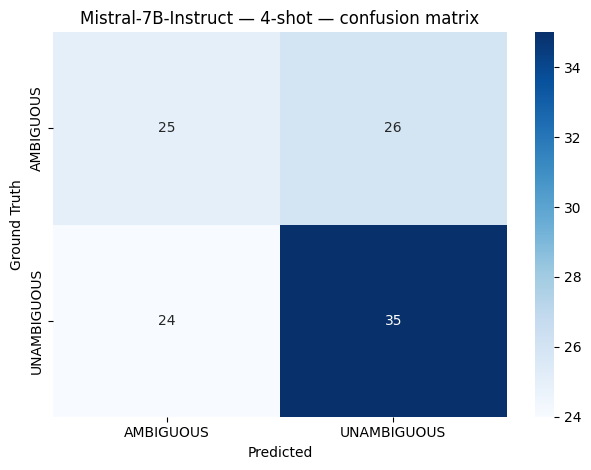

0.5454545454545454

In [ ]:
evaluate_results(dev_results_mistral7b_fewshot, "Mistral-7B-Instruct — 4-shot")

EUROLLM

In [ ]:
!pip install llama-cpp-python -q
!pip install huggingface_hub -q
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

model_path = hf_hub_download(
    repo_id="QuantFactory/EuroLLM-1.7B-Instruct-GGUF",
    filename="EuroLLM-1.7B-Instruct.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

llm = Llama(
    model_path=model_path,
    n_ctx=4096,            # needs larger context for 10-shot
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)

print("EuroLLM loaded")

EuroLLM-1.7B-Instruct.Q4_K_M.gguf:   0%|          | 0.00/1.05G [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--QuantFactory--EuroLLM-1.7B-Instruct-GGUF/snapshots/4126f034ddfe7fd39ca3378ae58d3b1d74065315/EuroLLM-1.7B-Instruct.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) < n_ctx_train (8192) -- the full capacity of the model will not be utilized


EuroLLM loaded


In [ ]:
# EuroLLM 1.7B
dev_results_euro_fewshot = run_evaluation_fewshot(
    prompt_dev_df,
    model_type="qwen",           # ChatML
    model_name="eurollm_1.7b"
)

100%|██████████| 110/110 [32:36<00:00, 17.79s/it]

Done. Errors: 4


# Euro LLM - 4shot


========== EuroLLM — 4-shot ==========
Valid predictions : 106
Errors            : 4

Accuracy: 0.4245

              precision    recall  f1-score   support

   AMBIGUOUS       0.43      0.88      0.58        48
 UNAMBIGUOUS       0.33      0.05      0.09        58

    accuracy                           0.42       106
   macro avg       0.38      0.46      0.33       106
weighted avg       0.38      0.42      0.31       106



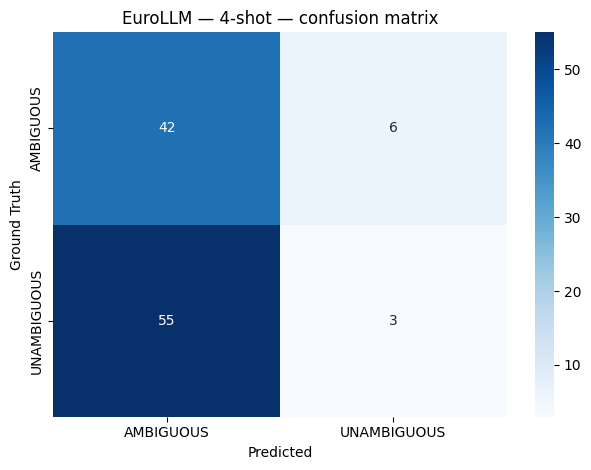

0.42452830188679247

In [ ]:
evaluate_results(dev_results_euro_fewshot, "EuroLLM — 4-shot")

MISTRAL API

In [ ]:
import requests
import json
import re

API_KEY = "#######################################"

In [ ]:
def classify_fewshot_detailed_api(requirement: str) -> dict:
    prompt_content = f"""You are an expert in software requirement analysis.

A requirement is ambiguous if it introduces real uncertainty in understanding
A requirement is ambiguous if:
- It uses vague terms (e.g., "quickly", "efficiently") that affect interpreta
- It has unclear pronoun references (e.g., "it", "they")
- It allows multiple reasonable interpretations
A requirement is NOT ambiguous if:
- It is understandable by an engineer
- It follows standard engineering wording
- It contains general terms that do not affect implementation
IMPORTANT:
- Do NOT classify as ambiguous for minor wording issues
- Do NOT classify as ambiguous just because the sentence is complex
- Do NOT ignore clear ambiguity
Be balanced:
- If ambiguity clearly affects understanding → ambiguous
- Otherwise → unambiguous


Examples:

Requirement: HCCS ISS Work will also be synchronized with RCN and Halifax-class related activities...
Classification: ambiguous

Requirement: The Contractor must provide in the Risk Management Plan, a risk management framework...
Classification: ambiguous

Requirement: The Relationship Charter describes common goals, desired behaviours, and joint governance...
Classification: unambiguous

Requirement: Commencing at Contract Award, the Contractor must collect performance data...
Classification: unambiguous

Return ONLY JSON:
{{
  "classification": "ambiguous or unambiguous",
  "explanation": "one clear sentence"
}}

Requirement:
"{requirement}"
"""

    response = requests.post(
        "https://api.mistral.ai/v1/chat/completions",
        headers={"Authorization": f"Bearer {API_KEY}"},
        json={
            "model": "mistral-small-latest",
            "messages": [{"role": "user", "content": prompt_content}],
            "max_tokens": 120,
            "temperature": 0.0
        }
    )

    raw = response.json()["choices"][0]["message"]["content"].strip()

    try:
        match = re.search(r'\{.*?\}', raw, re.DOTALL)
        if match:
            parsed = json.loads(match.group())
            label = parsed.get("classification", "ERROR").strip().lower()
            explanation = parsed.get("explanation", "")

            if "unambiguous" in label:
                final_label = "UNAMBIGUOUS"
            elif "ambiguous" in label:
                final_label = "AMBIGUOUS"
            else:
                final_label = "ERROR"

            return {"predicted": final_label, "explanation": explanation, "raw_output": raw}
    except (json.JSONDecodeError, AttributeError):
        pass

    raw_upper = raw.upper()
    if "UNAMBIGUOUS" in raw_upper:
        return {"predicted": "UNAMBIGUOUS", "explanation": "", "raw_output": raw}
    elif "AMBIGUOUS" in raw_upper:
        return {"predicted": "AMBIGUOUS", "explanation": "", "raw_output": raw}

    return {"predicted": "ERROR", "explanation": "", "raw_output": raw}

In [ ]:
dev_results_api_fewshot = run_evaluation_fewshot(
    prompt_dev_df, model_type="mistral_api", model_name="mistral_api"
)

100%|██████████| 110/110 [01:58<00:00,  1.08s/it]

Done. Errors: 0


# Mistral API - 4shot


========== MitsralAPI — 4-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.4364

              precision    recall  f1-score   support

   AMBIGUOUS       0.39      0.37      0.38        51
 UNAMBIGUOUS       0.48      0.49      0.48        59

    accuracy                           0.44       110
   macro avg       0.43      0.43      0.43       110
weighted avg       0.43      0.44      0.44       110



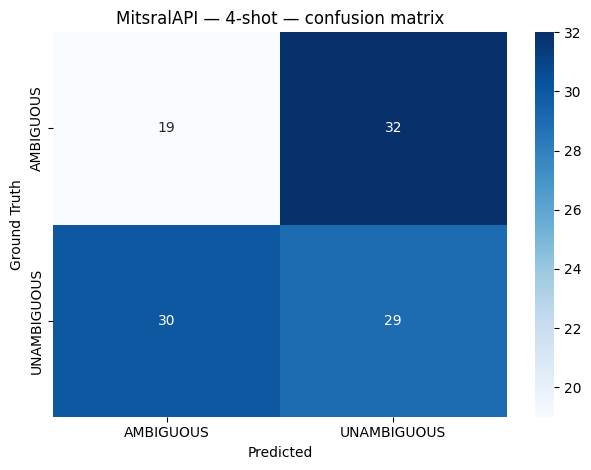

0.43636363636363634

In [ ]:
evaluate_results(dev_results_api_fewshot, "MitsralAPI — 4-shot")

QWEN 2.5B

In [ ]:
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

model_path = hf_hub_download(
    repo_id="bartowski/Qwen2.5-1.5B-Instruct-GGUF",
    filename="Qwen2.5-1.5B-Instruct-Q4_K_M.gguf"
)

llm = Llama(
    model_path=model_path,
    n_ctx=1024,
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)
print("Qwen 2.5 1.5B loaded")

Qwen2.5-1.5B-Instruct-Q4_K_M.gguf:   0%|          | 0.00/986M [00:00<?, ?B/s]

llama_context: n_ctx_seq (1024) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


Qwen 2.5 1.5B loaded


# Qwen 2.5 B - 4shot

100%|██████████| 110/110 [23:31<00:00, 12.84s/it]
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))

Done. Errors: 0

========== Qwen 2.5 1.5B — 10-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.4636

              precision    recall  f1-score   support

   AMBIGUOUS       0.46      1.00      0.63        51
 UNAMBIGUOUS       0.00      0.00      0.00        59

    accuracy                           0.46       110
   macro avg       0.23      0.50      0.32       110
weighted avg       0.21      0.46      0.29       110



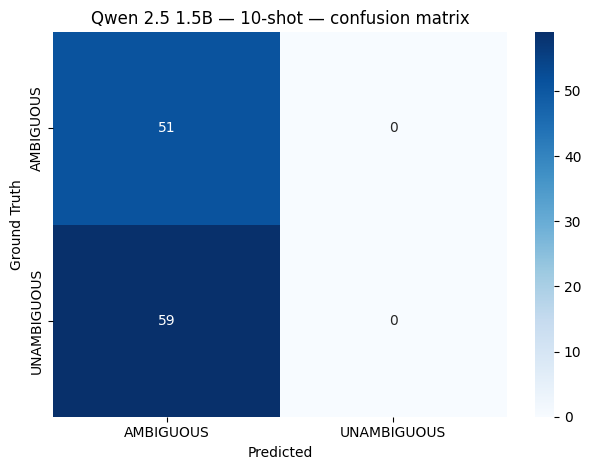

0.4636363636363636

In [ ]:
# Qwen 2.5
dev_results_qwen_fewshot = run_evaluation_fewshot(
    prompt_dev_df, model_type="qwen", model_name="qwen2.5_1.5b"
)
evaluate_results(dev_results_qwen_fewshot, "Qwen 2.5 1.5B — 10-shot")

LLama 3 8B

In [ ]:
!pip install llama-cpp-python -q
!pip install huggingface_hub -q

import os
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os
model_path = hf_hub_download(
    repo_id="bartowski/Meta-Llama-3-8B-Instruct-GGUF",
    filename="Meta-Llama-3-8B-Instruct-Q4_K_M.gguf"
)

llm = Llama(
    model_path=model_path,
    n_ctx=1024,
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)
print("Llama 3 8B loaded")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.0/59.0 MB 9.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.7 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Meta-Llama-3-8B-Instruct-Q4_K_M.gguf:   0%|          | 0.00/4.92G [00:00<?, ?B/s]

llama_context: n_ctx_seq (1024) < n_ctx_train (8192) -- the full capacity of the model will not be utilized


Llama 3 8B loaded


# Llama 3 8B - 4 shot

  0%|          | 0/110 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/llama_cpp/llama.py:1256: RuntimeWarning: Detected duplicate leading "<|begin_of_text|>" in prompt, this will likely reduce response quality, consider removing it...
  warnings.warn(
100%|██████████| 110/110 [1:26:42<00:00, 47.29s/it]


Done. Errors: 0

========== Llama 3 8B — 10-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.4636

              precision    recall  f1-score   support

   AMBIGUOUS       0.46      0.90      0.61        51
 UNAMBIGUOUS       0.50      0.08      0.14        59

    accuracy                           0.46       110
   macro avg       0.48      0.49      0.38       110
weighted avg       0.48      0.46      0.36       110



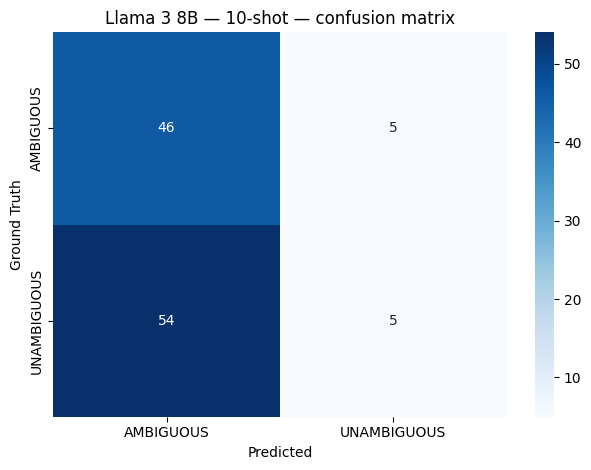

0.4636363636363636

In [ ]:
# Llama 3 8B
dev_results_llama_fewshot = run_evaluation_fewshot(
    prompt_dev_df, model_type="llama", model_name="llama3_8b"
)
evaluate_results(dev_results_llama_fewshot, "Llama 3 8B — 10-shot")

Checking prompt with Pronoun

In [ ]:
import requests, json, re
def classify_fewshot_detailed(requirement: str, model_type: str, examples_df=None) -> dict:

    prompt = f"""You are an expert in software requirement analysis specialising in pronoun reference ambiguity.

A requirement is AMBIGUOUS if it contains a pronoun (such as "it", "its", "they", "their", "them", "he", "his", "she", "this", "these") whose reference is UNCLEAR — meaning a reader cannot confidently determine what or who the pronoun refers to from the context provided.

A requirement is UNAMBIGUOUS if:
- All pronouns have a clear and unambiguous antecedent
- The meaning is clear even with pronouns present
- The pronoun refers to a single obvious entity in the sentence

IMPORTANT:
- Focus ONLY on whether pronoun references are clear
- Do NOT classify as ambiguous for complexity, vague terms, or missing details
- A pronoun is ambiguous only if it could plausibly refer to more than one entity

Examples from the domain:

Requirement: HCCS ISS Work will also be synchronized with RCN and Halifax-class related activities, and managed within the related DND business plans and budgets. The Contractor must incorporate Canada's objectives into its ISS Program, without limiting or affecting any other provision of the Contract.
Pronoun: its
Classification: ambiguous
Reason: "its" could refer to Canada or the Contractor — unclear antecedent.

Requirement: The Contractor must provide in the Risk Management Plan, a risk management framework that provides a governance structure by which risks are escalated to the appropriate decision level in a timely manner. The Contractor must include a Business Continuity Section as part of his Risk Management Plan.
Pronoun: his
Classification: ambiguous
Reason: "his" is gender-specific and unclear — the Contractor could be an organisation, not a person.

Requirement: The Relationship Charter describes common goals, desired behaviours, and joint governance. It will include a series of mutually agreed upon processes to increase collaboration.
Pronoun: It
Classification: unambiguous
Reason: "It" clearly refers to The Relationship Charter — single obvious antecedent.

Requirement: Commencing at Contract Award, the Contractor must collect performance data to support the PMF. The Contractor must develop and update a Performance Management Plan that describes how the Contractor will manage their performance for the duration of the Contract.
Pronoun: their
Classification: unambiguous
Reason: "their" clearly refers to the Contractor — unambiguous in context.

Return ONLY JSON:
{{
  "classification": "ambiguous or unambiguous",
  "explanation": "one sentence identifying the pronoun and whether its reference is clear or unclear"
}}

Requirement:
"{requirement}"
"""

    # Chat format wrapping — same as before
    if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
        full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
        stop_tokens = ["<|im_end|>", "<|im_start|>"]

    elif model_type == "phi":
        full_prompt = f"""<|system|>
You are an expert in software requirement analysis.<|end|>
<|user|>
{prompt}<|end|>
<|assistant|>
"""
        stop_tokens = ["<|end|>", "<|user|>"]

    elif model_type == "llama":
        full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
        stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

    else:
        raise ValueError(f"Unknown model_type: {model_type}")

    out = llm(
        full_prompt,
        max_tokens=150,
        temperature=0.0,
        stop=stop_tokens,
        echo=False
    )

    raw = out["choices"][0]["text"].strip()

    try:
        match = re.search(r'\{.*?\}', raw, re.DOTALL)
        if match:
            parsed = json.loads(match.group())
            label = parsed.get("classification", "ERROR").strip().lower()
            explanation = parsed.get("explanation", "")

            if "unambiguous" in label:
                final_label = "UNAMBIGUOUS"
            elif "ambiguous" in label:
                final_label = "AMBIGUOUS"
            else:
                final_label = "ERROR"

            return {"predicted": final_label, "explanation": explanation, "raw_output": raw}
    except (json.JSONDecodeError, AttributeError):
        pass

    raw_upper = raw.upper()
    if "UNAMBIGUOUS" in raw_upper:
        return {"predicted": "UNAMBIGUOUS", "explanation": "", "raw_output": raw}
    elif "AMBIGUOUS" in raw_upper:
        return {"predicted": "AMBIGUOUS", "explanation": "", "raw_output": raw}

    return {"predicted": "ERROR", "explanation": "", "raw_output": raw}

In [ ]:
from tqdm import tqdm
import pandas as pd
import time
def run_evaluation_fewshot(dataset_df, model_type: str, model_name: str):
    results = []

    for row in tqdm(dataset_df.itertuples(index=False), total=len(dataset_df)):
        try:
            if model_type == "mistral_api":
                result = classify_fewshot_detailed_api(row.Context)
                time.sleep(0.3)
            else:
                result = classify_fewshot_detailed(row.Context, model_type)

            results.append({
                "requirement"  : row.Context,
                "ground_truth" : row.DetectedAs,
                "predicted"    : result["predicted"],
                "explanation"  : result.get("explanation", ""),
                "raw_output"   : result.get("raw_output", "")
            })
        except Exception as e:
            results.append({
                "requirement"  : row.Context,
                "ground_truth" : row.DetectedAs,
                "predicted"    : "ERROR",
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        if len(results) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_fewshot.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_fewshot.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_results(dev_results, model_name: str):
    # Normalise both columns to uppercase
    dev_results["predicted_clean"]    = dev_results["predicted"].str.strip().str.upper()
    dev_results["ground_truth_clean"] = dev_results["ground_truth"].str.strip().str.upper()

    # Filter errors
    clean = dev_results[dev_results["predicted_clean"] != "ERROR"].copy()
    print(f"\n========== {model_name} ==========")
    print(f"Valid predictions : {len(clean)}")
    print(f"Errors            : {len(dev_results) - len(clean)}")

    y_true = clean["ground_truth_clean"]
    y_pred = clean["predicted_clean"]

    print(f"\nAccuracy: {accuracy_score(y_true, y_pred):.4f}")
    print("\n" + classification_report(
        y_true, y_pred,
        labels=["AMBIGUOUS", "UNAMBIGUOUS"],
        target_names=["AMBIGUOUS", "UNAMBIGUOUS"]
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=["AMBIGUOUS", "UNAMBIGUOUS"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["AMBIGUOUS", "UNAMBIGUOUS"],
                yticklabels=["AMBIGUOUS", "UNAMBIGUOUS"])
    plt.xlabel("Predicted")
    plt.ylabel("Ground Truth")
    plt.title(f"{model_name} — confusion matrix")
    plt.tight_layout()
    plt.show()

    return accuracy_score(y_true, y_pred)

EUROLLM

In [ ]:
!pip install llama-cpp-python -q
!pip install huggingface_hub -q
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

model_path = hf_hub_download(
    repo_id="QuantFactory/EuroLLM-1.7B-Instruct-GGUF",
    filename="EuroLLM-1.7B-Instruct.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

llm = Llama(
    model_path=model_path,
    n_ctx=4096,            # needs larger context for 10-shot
    n_threads=os.cpu_count(),
    n_batch=512,
    verbose=False
)

print("EuroLLM loaded")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.3/59.3 MB 17.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.5 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


EuroLLM-1.7B-Instruct.Q4_K_M.gguf:   0%|          | 0.00/1.05G [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--QuantFactory--EuroLLM-1.7B-Instruct-GGUF/snapshots/4126f034ddfe7fd39ca3378ae58d3b1d74065315/EuroLLM-1.7B-Instruct.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) < n_ctx_train (8192) -- the full capacity of the model will not be utilized


EuroLLM loaded


In [ ]:
# EuroLLM 1.7B
dev_results_euro_fewshot = run_evaluation_fewshot(
    prompt_dev_df,
    model_type="qwen",           # ChatML
    model_name="eurollm_1.7b"
)

100%|██████████| 110/110 [25:49<00:00, 14.08s/it]

Done. Errors: 0


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



========== EuroLLM — 4-shot ==========
Valid predictions : 110
Errors            : 0

Accuracy: 0.4636

              precision    recall  f1-score   support

   AMBIGUOUS       0.46      1.00      0.63        51
 UNAMBIGUOUS       0.00      0.00      0.00        59

    accuracy                           0.46       110
   macro avg       0.23      0.50      0.32       110
weighted avg       0.21      0.46      0.29       110



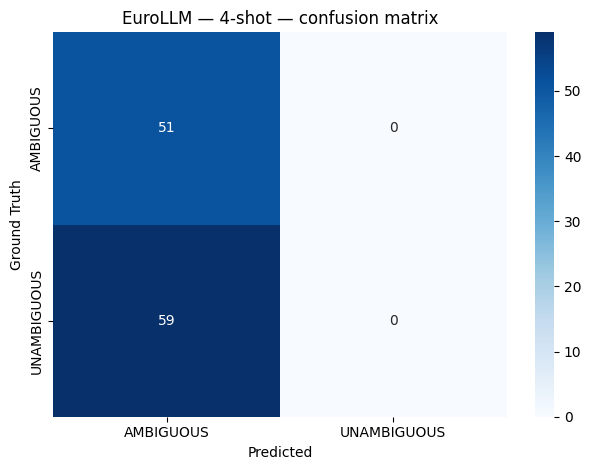

0.4636363636363636

In [ ]:
evaluate_results(dev_results_euro_fewshot, "EuroLLM — 4-shot")